# 🏠 House Price Prediction with Linear Regression
**Simple & multiple linear regression from scratch to interpretation**

**Objective:** Implement and understand simple and multiple linear regression.
**Tools:** Scikit-learn, Pandas, Matplotlib (+ NumPy / SciPy for diagnostics)

**Pipeline**
1. Import & preprocess the dataset
2. Split into train and test sets
3. Fit a **simple** (price ~ area) and a **multiple** linear regression model
4. Evaluate with **MAE, MSE, RMSE, R²**
5. Plot the regression line & interpret the coefficients
6. Check the regression assumptions
7. Cross-validation, a log-price comparison and a sample prediction

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
os.makedirs("images", exist_ok=True)   # plots are saved here
RANDOM_STATE = 42
print("✅ Libraries imported")

✅ Libraries imported


## 📥 Step 1: Import & Explore the Dataset

In [2]:
# Auto-detect the housing CSV (works on Kaggle via "+ Add Input" AND locally from the data/ folder)
csv_path = None
for root_dir in ["/kaggle/input", "data"]:
    for dirname, _, filenames in os.walk(root_dir):
        for f in filenames:
            if not f.lower().endswith(".csv"):
                continue
            p = os.path.join(dirname, f)
            try:
                cols = pd.read_csv(p, nrows=1).columns
            except Exception:
                continue
            if {"price", "area", "bedrooms", "bathrooms"}.issubset(cols):
                csv_path = csv_path or p

if csv_path is None:
    raise FileNotFoundError("Housing CSV not found. Add the dataset on Kaggle or place Housing.csv in data/.")

print("Using file:", csv_path)
df = pd.read_csv(csv_path)
print("Shape:", df.shape)
df.head()

Using file: data/Housing.csv
Shape: (545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 55.5 KB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
price,545.00,"4,766,729.25","1,870,439.62","1,750,000.00","3,430,000.00","4,340,000.00","5,740,000.00","13,300,000.00"
area,545.00,"5,150.54","2,170.14","1,650.00","3,600.00","4,600.00","6,360.00","16,200.00"
bedrooms,545.00,2.97,0.74,1.00,2.00,3.00,3.00,6.00
bathrooms,545.00,1.29,0.50,1.00,1.00,1.00,2.00,4.00
stories,545.00,1.81,0.87,1.00,1.00,2.00,2.00,4.00
parking,545.00,0.69,0.86,0.00,0.00,0.00,1.00,3.00


In [5]:
print("Missing values:\n", df.isnull().sum()[df.isnull().sum() > 0] if df.isnull().any().any() else "None ✅")
print("\nDuplicate rows:", df.duplicated().sum())
print("\nCategorical columns:")
for c in df.select_dtypes("object").columns:
    print(f"  {c:17s}", df[c].value_counts().to_dict())

Missing values:
 None ✅

Duplicate rows: 0

Categorical columns:
  mainroad          {'yes': 468, 'no': 77}
  guestroom         {'no': 448, 'yes': 97}
  basement          {'no': 354, 'yes': 191}
  hotwaterheating   {'no': 520, 'yes': 25}
  airconditioning   {'no': 373, 'yes': 172}
  prefarea          {'no': 417, 'yes': 128}
  furnishingstatus  {'semi-furnished': 227, 'unfurnished': 178, 'furnished': 140}


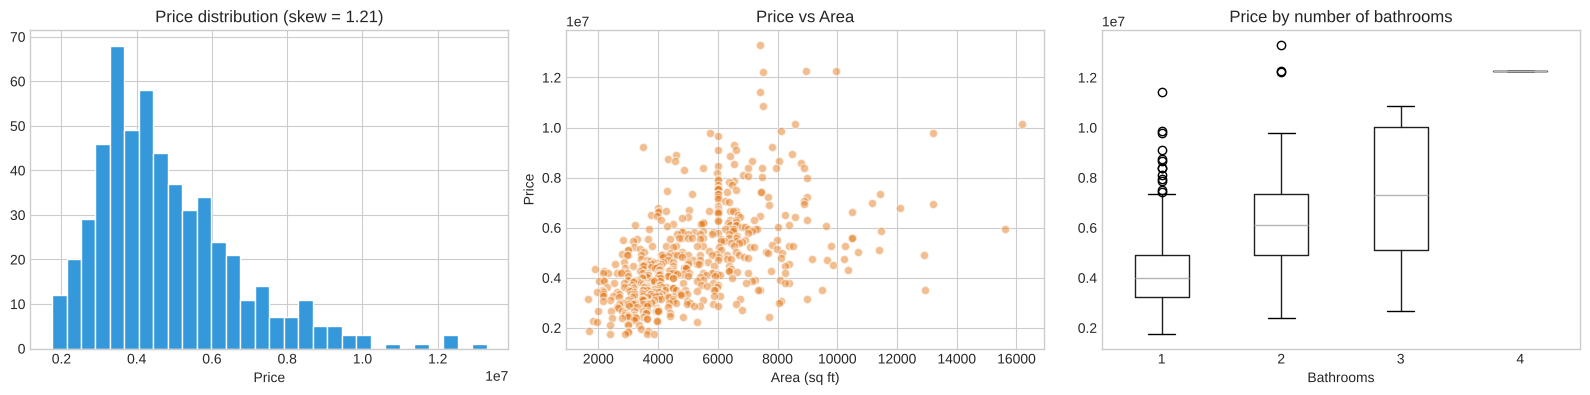

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

axes[0].hist(df["price"], bins=30, color="#3498db", edgecolor="white")
axes[0].set_title(f"Price distribution (skew = {df['price'].skew():.2f})")
axes[0].set_xlabel("Price")

axes[1].scatter(df["area"], df["price"], alpha=0.5, color="#e67e22", edgecolor="white")
axes[1].set_title("Price vs Area")
axes[1].set_xlabel("Area (sq ft)"); axes[1].set_ylabel("Price")

df.boxplot(column="price", by="bathrooms", ax=axes[2], grid=False)
axes[2].set_title("Price by number of bathrooms"); axes[2].set_xlabel("Bathrooms")
plt.suptitle("")
plt.tight_layout()
plt.savefig("images/01_price_exploration.png", dpi=150, bbox_inches="tight")
plt.show()

### 📝 Observations
- **545 houses, 13 columns**, no missing values and no duplicate rows
- 6 numeric features (`price`, `area`, `bedrooms`, `bathrooms`, `stories`, `parking`) and 7 categorical ones (6 yes/no + `furnishingstatus`)
- `price` is **right-skewed** (skew ≈ 1.21): a few very expensive houses
- Price rises with area and with the number of bathrooms
- The dataset does not state the currency, so prices are shown as plain numbers

## 🧹 Preprocessing
- **yes/no columns → 1/0** (binary encoding)
- **`furnishingstatus` → one-hot encoding** with `drop_first=True` (the dropped baseline is *furnished*), which avoids the dummy-variable trap
- No scaling is needed for ordinary least squares; scaling is only used later to **compare** coefficients
- IQR "outliers" exist in `price` (15) and `area` (12), but they are real houses, so they are **kept**

In [7]:
data = df.copy()

yes_no = ["mainroad", "guestroom", "basement", "hotwaterheating", "airconditioning", "prefarea"]
for c in yes_no:
    data[c] = data[c].map({"yes": 1, "no": 0})

data = pd.get_dummies(data, columns=["furnishingstatus"], drop_first=True, dtype=int)

print("Shape after encoding:", data.shape)
print("Any nulls left:", data.isnull().any().any())
data.head()

Shape after encoding: (545, 14)
Any nulls left: False


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,0,0
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,0,0
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,1,0
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,0,0
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,0,0


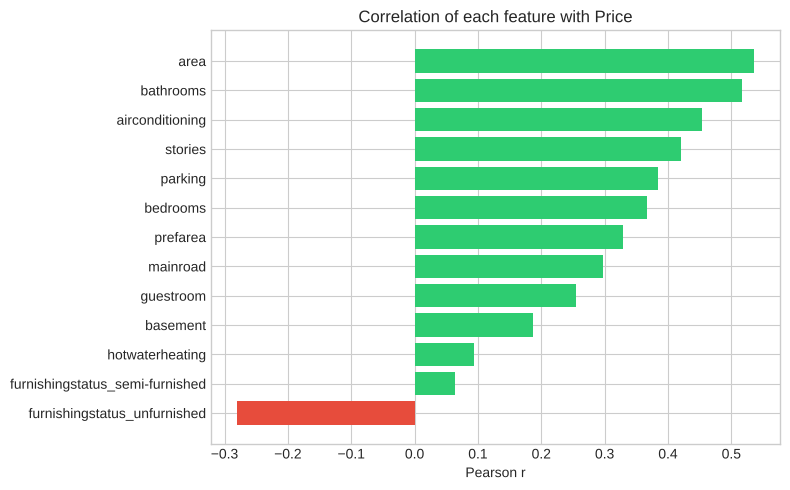

furnishingstatus_unfurnished      -0.28
furnishingstatus_semi-furnished    0.06
hotwaterheating                    0.09
basement                           0.19
guestroom                          0.26
mainroad                           0.30
prefarea                           0.33
bedrooms                           0.37
parking                            0.38
stories                            0.42
airconditioning                    0.45
bathrooms                          0.52
area                               0.54
Name: price, dtype: float64

In [8]:
# Correlation of every feature with price
corr_price = data.corr()["price"].drop("price").sort_values()
plt.figure(figsize=(8, 5))
plt.barh(corr_price.index, corr_price.values,
         color=["#e74c3c" if v < 0 else "#2ecc71" for v in corr_price.values])
plt.title("Correlation of each feature with Price")
plt.xlabel("Pearson r")
plt.tight_layout()
plt.savefig("images/02_correlation_with_price.png", dpi=150, bbox_inches="tight")
plt.show()
corr_price.round(3)

## ✂️ Step 2: Train–Test Split
80% of the data to train the model, 20% held back to test it on **unseen** houses (`random_state=42` for reproducibility).

In [9]:
X = data.drop(columns="price")
y = data["price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Features used:", list(X.columns))

Train: (436, 13) | Test: (109, 13)
Features used: ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus_semi-furnished', 'furnishingstatus_unfurnished']


## 📈 Step 3a: Simple Linear Regression (`price ~ area`)
One feature, one line: **price = intercept + slope × area**

In [10]:
simple = LinearRegression()
simple.fit(X_train[["area"]], y_train)

print(f"Intercept : {simple.intercept_:,.2f}")
print(f"Slope     : {simple.coef_[0]:,.2f}  (price units per extra sq ft)")
print(f"\nEquation  : price = {simple.intercept_:,.0f} + {simple.coef_[0]:,.2f} x area")

Intercept : 2,512,254.26
Slope     : 425.73  (price units per extra sq ft)

Equation  : price = 2,512,254 + 425.73 x area


### 📉 Regression line

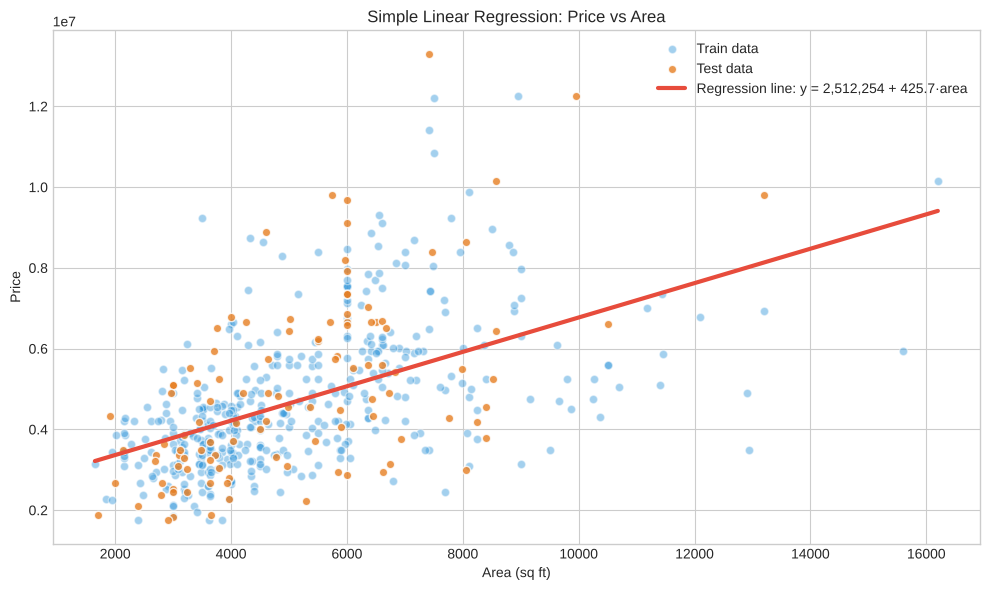

In [11]:
line_x = np.linspace(X["area"].min(), X["area"].max(), 100).reshape(-1, 1)
line_y = simple.predict(pd.DataFrame(line_x, columns=["area"]))

plt.figure(figsize=(10, 6))
plt.scatter(X_train["area"], y_train, alpha=0.45, color="#3498db", label="Train data", edgecolor="white")
plt.scatter(X_test["area"], y_test, alpha=0.8, color="#e67e22", label="Test data", edgecolor="white")
plt.plot(line_x, line_y, color="#e74c3c", linewidth=3,
         label=f"Regression line: y = {simple.intercept_:,.0f} + {simple.coef_[0]:,.1f}·area")
plt.xlabel("Area (sq ft)"); plt.ylabel("Price")
plt.title("Simple Linear Regression: Price vs Area")
plt.legend()
plt.tight_layout()
plt.savefig("images/03_simple_regression_line.png", dpi=150, bbox_inches="tight")
plt.show()

## 📊 Step 3b: Multiple Linear Regression (all features)
**price = b0 + b1·area + b2·bedrooms + b3·bathrooms + ...** Each coefficient is the effect of that feature
*while holding all the others constant*.

In [12]:
multi = LinearRegression()
multi.fit(X_train, y_train)

print(f"Intercept: {multi.intercept_:,.2f}\n")
coef_df = pd.DataFrame({"Feature": X.columns, "Coefficient": multi.coef_}).sort_values("Coefficient", ascending=False)
coef_df.reset_index(drop=True)

Intercept: 260,032.36



,Feature,Coefficient
0,bathrooms,"1,094,444.79"
1,airconditioning,"791,426.74"
2,hotwaterheating,"684,649.89"
3,prefarea,"629,890.57"
4,stories,"407,476.59"
5,basement,"390,251.18"
6,mainroad,"367,919.95"
7,guestroom,"231,610.04"
8,parking,"224,841.91"
9,bedrooms,"76,778.70"


## 🎯 Step 4: Evaluate the Models (MAE, MSE, RMSE, R²)
- **MAE**: average absolute error, in price units
- **MSE**: average squared error, which punishes big mistakes more
- **RMSE**: √MSE, back in price units
- **R²**: share of the variance in price the model explains (1 = perfect, 0 = no better than predicting the mean)

In [13]:
def evaluate(model, Xa, ya, name):
    pred = model.predict(Xa)
    mse = mean_squared_error(ya, pred)
    n, k = Xa.shape
    r2 = r2_score(ya, pred)
    return {"Model": name,
            "MAE": mean_absolute_error(ya, pred),
            "MSE": mse,
            "RMSE": np.sqrt(mse),
            "R²": r2,
            "Adj. R²": 1 - (1 - r2) * (n - 1) / (n - k - 1)}

baseline = type("Mean", (), {"predict": lambda self, Xa: np.full(len(Xa), y_train.mean())})()

results = pd.DataFrame([
    evaluate(baseline, X_test, y_test, "Baseline (always predict the mean)"),
    evaluate(simple, X_train[["area"]], y_train, "Simple LR - TRAIN"),
    evaluate(simple, X_test[["area"]], y_test, "Simple LR - TEST"),
    evaluate(multi, X_train, y_train, "Multiple LR - TRAIN"),
    evaluate(multi, X_test, y_test, "Multiple LR - TEST"),
]).set_index("Model")

pd.options.display.float_format = lambda v: f"{v:,.3f}" if abs(v) < 10 else f"{v:,.0f}"
display(results)
pd.options.display.float_format = lambda v: f"{v:,.2f}"

,MAE,MSE,RMSE,R²,Adj. R²
Model,,,,,
Baseline (always predict the mean),"1,748,625","5,145,176,852,226","2,268,298",-0.018,-0.157
Simple LR - TRAIN,"1,092,586","2,204,738,681,379","1,484,836",0.285,0.283
Simple LR - TEST,"1,474,748","3,675,286,604,768","1,917,104",0.273,0.266
Multiple LR - TRAIN,"719,243","968,358,188,441","984,052",0.686,0.676
Multiple LR - TEST,"970,043","1,754,318,687,331","1,324,507",0.653,0.605


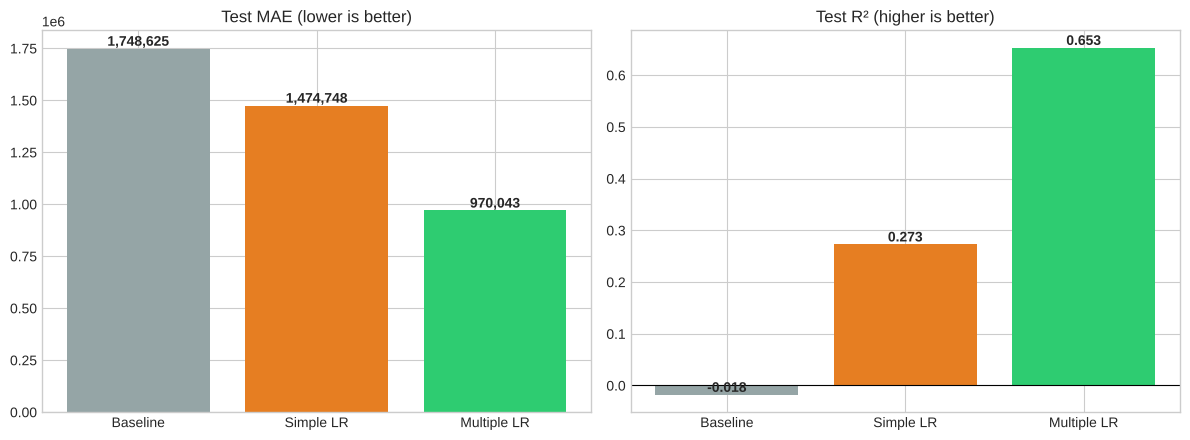

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
names = ["Baseline", "Simple LR", "Multiple LR"]
test_rows = ["Baseline (always predict the mean)", "Simple LR - TEST", "Multiple LR - TEST"]

axes[0].bar(names, results.loc[test_rows, "MAE"], color=["#95a5a6", "#e67e22", "#2ecc71"])
axes[0].set_title("Test MAE (lower is better)")
for i, v in enumerate(results.loc[test_rows, "MAE"]):
    axes[0].text(i, v, f"{v:,.0f}", ha="center", va="bottom", fontweight="bold")

axes[1].bar(names, results.loc[test_rows, "R²"], color=["#95a5a6", "#e67e22", "#2ecc71"])
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("Test R² (higher is better)")
for i, v in enumerate(results.loc[test_rows, "R²"]):
    axes[1].text(i, v, f"{v:.3f}", ha="center", va="bottom", fontweight="bold")
plt.tight_layout()
plt.savefig("images/04_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### 📝 Observations (model performance)
- **Baseline** (always predicting the average price) has R² ≈ −0.02: any useful model must beat this
- **Simple LR (area only)**: test **R² ≈ 0.27**, MAE ≈ 1,474,748. Area alone explains only about a quarter of the price variation
- **Multiple LR**: test **R² ≈ 0.65**, MAE ≈ 970,043, RMSE ≈ 1,324,507. Adding the other features more than doubles the explained variance
- Train R² (0.69) vs test R² (0.65): a small gap, so there is **no serious overfitting**
- Adjusted R² on the test set is ≈ 0.61 (it penalises the 13 features used)

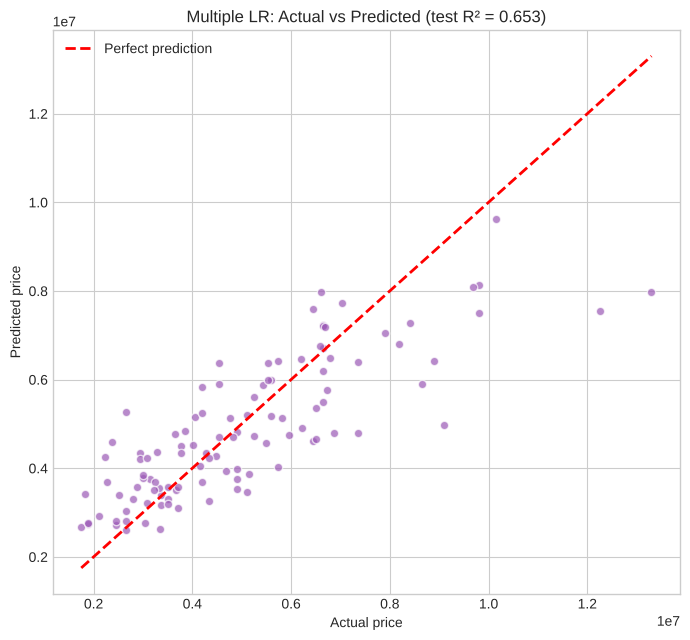

In [15]:
pred_test = multi.predict(X_test)

plt.figure(figsize=(7, 6.5))
plt.scatter(y_test, pred_test, alpha=0.7, color="#9b59b6", edgecolor="white")
lims = [min(y_test.min(), pred_test.min()), max(y_test.max(), pred_test.max())]
plt.plot(lims, lims, "r--", linewidth=2, label="Perfect prediction")
plt.xlabel("Actual price"); plt.ylabel("Predicted price")
plt.title(f"Multiple LR: Actual vs Predicted (test R² = {r2_score(y_test, pred_test):.3f})")
plt.legend()
plt.tight_layout()
plt.savefig("images/05_actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()

## 🔍 Step 5: Interpret the Coefficients
### 5a. Raw coefficients (effect in price units, other features held constant)

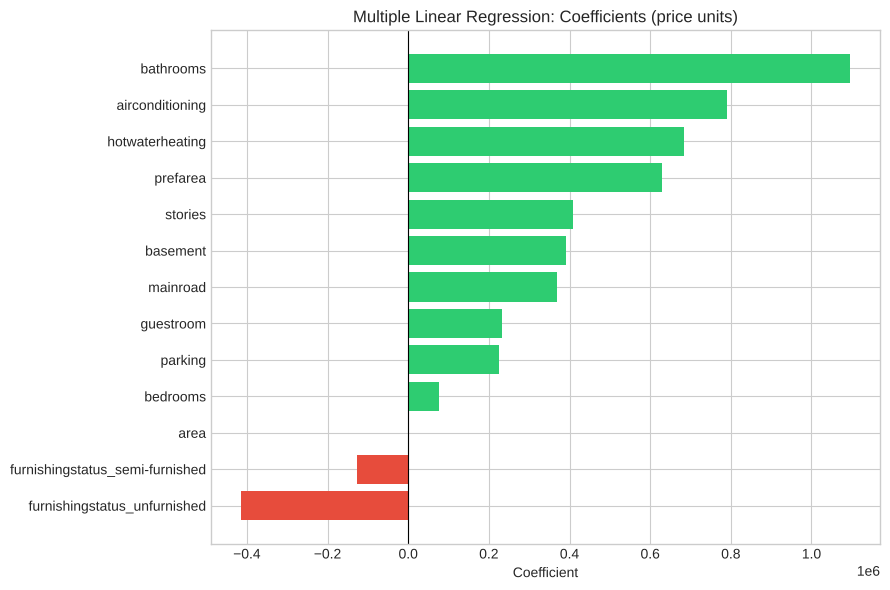

In [16]:
coef_sorted = coef_df.sort_values("Coefficient")
plt.figure(figsize=(9, 6))
plt.barh(coef_sorted["Feature"], coef_sorted["Coefficient"],
         color=["#e74c3c" if v < 0 else "#2ecc71" for v in coef_sorted["Coefficient"]])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Multiple Linear Regression: Coefficients (price units)")
plt.xlabel("Coefficient")
plt.tight_layout()
plt.savefig("images/06_coefficients.png", dpi=150, bbox_inches="tight")
plt.show()

### 5b. Standardized coefficients: which features matter *most*?
Raw coefficients are not comparable because features have different units (1 sq ft vs 1 bathroom).
After standardizing every feature, each coefficient means *"price change for a 1-standard-deviation increase"*.

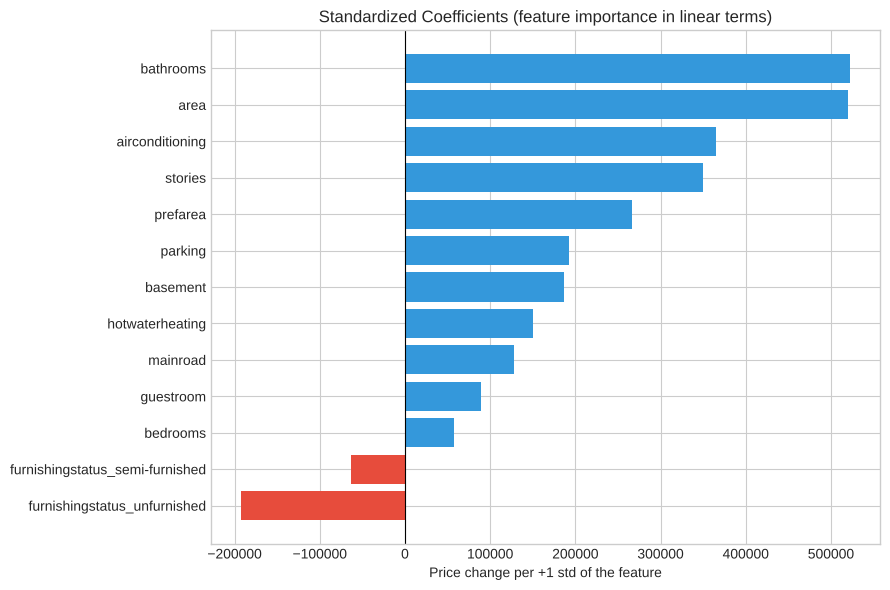

bathrooms                          521,879.00
area                               519,552.00
airconditioning                    365,157.00
stories                            349,251.00
prefarea                           266,656.00
parking                            192,006.00
basement                           187,068.00
hotwaterheating                    149,863.00
mainroad                           128,499.00
guestroom                           88,769.00
bedrooms                            57,350.00
furnishingstatus_semi-furnished    -62,837.00
furnishingstatus_unfurnished      -192,016.00
dtype: float64

In [17]:
scaler = StandardScaler().fit(X_train)
multi_std = LinearRegression().fit(scaler.transform(X_train), y_train)

std_coef = pd.Series(multi_std.coef_, index=X.columns).sort_values()
plt.figure(figsize=(9, 6))
plt.barh(std_coef.index, std_coef.values, color=["#e74c3c" if v < 0 else "#3498db" for v in std_coef.values])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Standardized Coefficients (feature importance in linear terms)")
plt.xlabel("Price change per +1 std of the feature")
plt.tight_layout()
plt.savefig("images/07_standardized_coefficients.png", dpi=150, bbox_inches="tight")
plt.show()
std_coef.sort_values(ascending=False).round(0)

### 📝 Interpretation (holding all other features constant)
| Feature | Coefficient | Meaning |
|---|---|---|
| `area` | **+236** | each extra sq ft adds ≈ 236 to the price |
| `bathrooms` | **+1,094,445** | each extra bathroom adds ≈ 1.09 million: the largest raw effect |
| `airconditioning` | **+791,427** | houses with A/C cost ≈ 0.79 million more |
| `hotwaterheating` | +684,650 | big coefficient, but only **25 houses** have it, so treat it with caution |
| `prefarea` | +629,891 | being in a preferred area adds ≈ 0.63 million |
| `stories` | +407,477 | each extra storey adds ≈ 0.41 million |
| `basement`, `mainroad`, `guestroom`, `parking` | +390,251 / +367,920 / +231,610 / +224,842 | positive premiums |
| `bedrooms` | +76,779 | small effect once area and bathrooms are accounted for |
| `furnishingstatus_semi-furnished` | −126,882 | vs the *furnished* baseline |
| `furnishingstatus_unfurnished` | −413,645 | unfurnished houses sell for ≈ 0.41 million less than furnished ones |

**Most influential in standardized terms:** `bathrooms` (≈ 521,879) and `area` (≈ 519,552), then `airconditioning`, `stories` and `prefarea`.
**Intercept** ≈ 260,032 is the predicted price of a house with every feature at 0 (not physically meaningful on its own).

## 🧪 Step 6: Check the Regression Assumptions

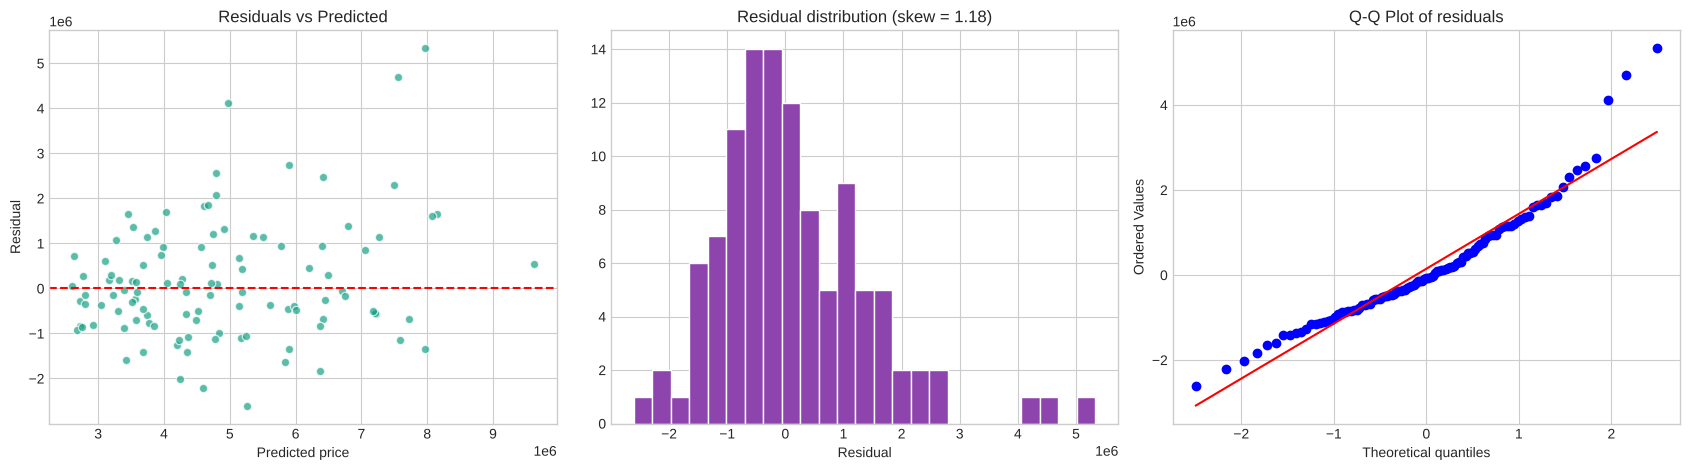

Shapiro-Wilk normality test: statistic = 0.932, p-value = 3.28e-05
Mean of residuals: 146,055  |  Std: 1,322,510


In [18]:
residuals = y_test - pred_test

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# 1) Linearity & homoscedasticity
axes[0].scatter(pred_test, residuals, alpha=0.7, color="#16a085", edgecolor="white")
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Predicted price"); axes[0].set_ylabel("Residual")
axes[0].set_title("Residuals vs Predicted")

# 2) Normality of residuals
axes[1].hist(residuals, bins=25, color="#8e44ad", edgecolor="white")
axes[1].set_title(f"Residual distribution (skew = {residuals.skew():.2f})")
axes[1].set_xlabel("Residual")

# 3) Q-Q plot
stats.probplot(residuals, dist="norm", plot=axes[2])
axes[2].set_title("Q-Q Plot of residuals")

plt.tight_layout()
plt.savefig("images/08_residual_diagnostics.png", dpi=150, bbox_inches="tight")
plt.show()

stat, p = stats.shapiro(residuals)
print(f"Shapiro-Wilk normality test: statistic = {stat:.3f}, p-value = {p:.2e}")
print(f"Mean of residuals: {residuals.mean():,.0f}  |  Std: {residuals.std():,.0f}")

In [19]:
# Multicollinearity: Variance Inflation Factor (VIF > 5 is a warning sign)
vif = {}
for col in X.columns:
    others = X.drop(columns=col)
    r2 = LinearRegression().fit(others, X[col]).score(others, X[col])
    vif[col] = 1 / (1 - r2)
vif_df = pd.DataFrame({"VIF": vif}).sort_values("VIF", ascending=False)
vif_df

,VIF
furnishingstatus_unfurnished,1.67
furnishingstatus_semi-furnished,1.58
stories,1.48
bedrooms,1.37
area,1.33
basement,1.32
bathrooms,1.29
guestroom,1.21
parking,1.21
airconditioning,1.21


### 📝 Assumption check results
| Assumption | Result |
|---|---|
| **Linearity** | Residuals scatter around 0 with no strong curve → acceptable |
| **Independence** | Rows are separate houses, with no time order → acceptable |
| **Homoscedasticity** | The spread of residuals grows a little with the predicted price (funnel shape) → **mild violation** |
| **Normality of residuals** | Right-skewed (skew ≈ 1.18) and Shapiro p ≈ 3e-5 → **violated** (a few expensive houses are under-predicted) |
| **No multicollinearity** | All VIFs are between **1.04 and 1.67** (far below 5) → **fine** |

Predictions are still usable, but p-values and confidence intervals should be treated with care.
A common fix is to model **log(price)**, tried below.

## 🔁 Step 7: Cross-Validation (is the R² stable?)

R² per fold : [0.653 0.712 0.493 0.658 0.646]
Mean R²     : 0.632  (± 0.074)


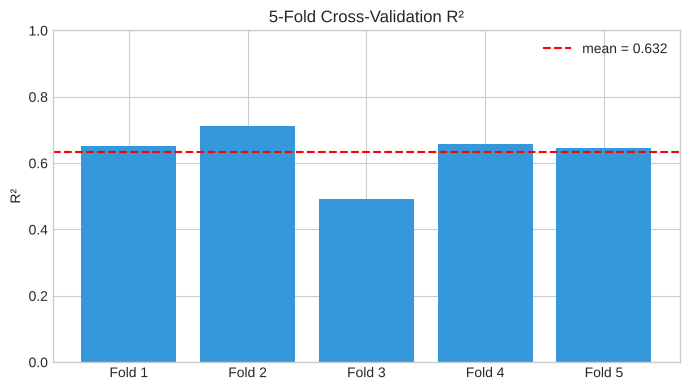

In [20]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(LinearRegression(), X, y, cv=cv, scoring="r2")

print("R² per fold :", np.round(cv_scores, 3))
print(f"Mean R²     : {cv_scores.mean():.3f}  (± {cv_scores.std():.3f})")

plt.figure(figsize=(7, 4))
plt.bar([f"Fold {i}" for i in range(1, 6)], cv_scores, color="#3498db")
plt.axhline(cv_scores.mean(), color="red", linestyle="--", label=f"mean = {cv_scores.mean():.3f}")
plt.ylim(0, 1); plt.ylabel("R²"); plt.title("5-Fold Cross-Validation R²")
plt.legend()
plt.tight_layout()
plt.savefig("images/09_cross_validation.png", dpi=150, bbox_inches="tight")
plt.show()

**Cross-validated R² ≈ 0.63 (± 0.07)**, in line with the test score of 0.65, so the model's performance is stable and not just a lucky split.

## 🔄 Bonus: Does modelling log(price) help?

In [21]:
log_model = LinearRegression().fit(X_train, np.log(y_train))
pred_log = np.exp(log_model.predict(X_test))      # back to price units

comparison = pd.DataFrame({
    "MAE": [mean_absolute_error(y_test, pred_test), mean_absolute_error(y_test, pred_log)],
    "RMSE": [np.sqrt(mean_squared_error(y_test, pred_test)), np.sqrt(mean_squared_error(y_test, pred_log))],
    "R² (price scale)": [r2_score(y_test, pred_test), r2_score(y_test, pred_log)],
}, index=["Linear on price", "Linear on log(price)"])
pd.options.display.float_format = lambda v: f"{v:,.3f}" if abs(v) < 10 else f"{v:,.0f}"
display(comparison)
pd.options.display.float_format = lambda v: f"{v:,.2f}"

log_resid = np.log(y_test) - log_model.predict(X_test)
print(f"Residual skew: price model = {residuals.skew():.2f}  vs  log model = {log_resid.skew():.2f}")

,MAE,RMSE,R² (price scale)
Linear on price,"970,043","1,324,507",0.653
Linear on log(price),"960,123","1,314,648",0.658


Residual skew: price model = 1.18  vs  log model = -0.12


The log model gives a **slightly better** fit (R² ≈ 0.658 vs 0.653, MAE ≈ 960,123 vs 970,043) and makes errors proportional to price,
but the gain is small. The plain model stays the main one because its coefficients are directly readable in price units.

## 🏡 Predict the price of a new house

In [22]:
new_house = pd.DataFrame([{
    "area": 6000, "bedrooms": 3, "bathrooms": 2, "stories": 2,
    "mainroad": 1, "guestroom": 0, "basement": 0, "hotwaterheating": 0,
    "airconditioning": 1, "parking": 1, "prefarea": 1,
    "furnishingstatus_semi-furnished": 1, "furnishingstatus_unfurnished": 0,
}])[X.columns]

print(f"Predicted price: {multi.predict(new_house)[0]:,.0f}")
print(f"Typical error (test MAE): ± {mean_absolute_error(y_test, pred_test):,.0f}")

Predicted price: 6,797,221
Typical error (test MAE): ± 970,043


## ✅ Conclusion
- A **simple regression on area alone** explains only ≈ 27% of price variation, so one feature is not enough
- A **multiple regression with all 12 features** reaches **test R² ≈ 0.65, MAE ≈ 970 thousand**, with stable cross-validation (≈ 0.63) and no overfitting
- **Bathrooms, area, air conditioning, stories and preferred area** are the strongest drivers of price; unfurnished houses sell for less
- Multicollinearity is not a problem (all VIF < 1.7), but residuals are **right-skewed** with mild heteroscedasticity, so a log transform or a non-linear model could improve results

## 🎤 Interview Questions: Short Answers
1. **What assumptions does linear regression make?** Linearity between features and target, independent errors, constant error variance (homoscedasticity), normally distributed residuals (needed for inference, not for fitting) and no severe multicollinearity.
2. **How do you interpret the coefficients?** Each coefficient is the change in the target for a 1-unit increase in that feature, holding the others constant. The intercept is the prediction when all features are 0. For dummy variables, it is the difference from the baseline category. Standardize features to compare importance.
3. **What is R² and its significance?** R² = 1 − SS_residual / SS_total, the share of target variance the model explains. 1 is perfect and 0 equals predicting the mean (it can go negative on test data). Adjusted R² penalises useless features. A high R² does not by itself mean a good or causal model.
4. **When would you prefer MSE over MAE?** When large errors are especially costly (MSE squares them), and for optimisation, since MSE is smooth and differentiable and is exactly what OLS minimises. MAE is preferred when outliers should not dominate, and it stays in the original units.
5. **How do you detect multicollinearity?** The correlation matrix, VIF (> 5 or 10 is a warning), the condition number, and unstable or sign-flipping coefficients. Fix it by dropping or combining features, or by using Ridge regression or PCA.
6. **Simple vs multiple regression?** Simple uses one predictor (y = b0 + b1·x, a line). Multiple uses two or more predictors (a hyperplane), and each coefficient is adjusted for the other features.
7. **Can linear regression be used for classification?** Not well. Outputs are unbounded and are not probabilities, so thresholding is fragile and sensitive to outliers. Logistic regression is the right tool.
8. **What if the assumptions are violated?** Coefficients may be biased or inefficient, standard errors, p-values and confidence intervals become unreliable, and predictions get worse. Fixes include transforming variables (log), adding polynomial or interaction terms, robust standard errors, weighted least squares, regularisation, or a non-linear model.